In [1]:
import pandas as pd
df = pd.read_csv("../data/raw/seer_raw.csv")
print(df.shape)
list(df.columns)

(472104, 17)


['Survival months',
 'Vital status recode (study cutoff used)',
 'SEER cause-specific death classification',
 'Age recode with single ages and 85+',
 'Race recode (White, Black, Other)',
 'Sex',
 'Origin recode NHIA (Hispanic, Non-Hisp)',
 'Year of diagnosis',
 'Site recode ICD-O-3/WHO 2008',
 'Histologic Type ICD-O-3',
 'Grade Recode (thru 2017)',
 'Tumor Size Over Time Recode (1988+)',
 'Combined Summary Stage with Expanded Regional Codes (2004+)',
 'Regional nodes positive (1988+)',
 'Radiation recode',
 'Chemotherapy recode (yes, no/unk)',
 'RX Summ--Surg Prim Site (1998-2022)']

In [2]:
df = df.rename(columns={
    "Survival months": "surv_months",
    "Vital status recode (study cutoff used)": "vital_status",
    "SEER cause-specific death classification": "cause_death",
    "Age recode with single ages and 85+": "age_raw",
    "Race recode (White, Black, Other)": "race",
    "Origin recode NHIA (Hispanic, Non-Hisp)": "origin",
    "Year of diagnosis": "year_dx",
    "Combined Summary Stage with Expanded Regional Codes (2004+)": "stage",
})
df.columns

Index(['surv_months', 'vital_status', 'cause_death', 'age_raw', 'race', 'Sex',
       'origin', 'year_dx', 'Site recode ICD-O-3/WHO 2008',
       'Histologic Type ICD-O-3', 'Grade Recode (thru 2017)',
       'Tumor Size Over Time Recode (1988+)', 'stage',
       'Regional nodes positive (1988+)', 'Radiation recode',
       'Chemotherapy recode (yes, no/unk)',
       'RX Summ--Surg Prim Site (1998-2022)'],
      dtype='object')

In [3]:
df["surv_months"] = pd.to_numeric(df["surv_months"], errors="coerce")
df["age"] = pd.to_numeric(df["age_raw"].str.extract(r"(\d+)")[0], errors="coerce")
df[["surv_months", "age"]].describe()

,surv_months,age
count,472104.000000,472104.000000
mean,73.902365,64.829489
std,63.345058,13.822246
min,0.000000,0.000000
25%,19.000000,55.000000
50%,58.000000,65.000000
75%,116.000000,76.000000
max,239.000000,85.000000


In [4]:
df["event_overall"] = (df["vital_status"] == "Dead").astype(int)
df["event_cancer"] = (df["cause_death"] == "Dead (attributable to this cancer dx)").astype(int)
df[["event_overall", "event_cancer"]].mean()
print(df["vital_status"].value_counts(), "\n")
print(df["cause_death"].value_counts(), "\n")
print(df["stage"].value_counts(dropna=False))

vital_status
Dead     273053
Alive    199051
Name: count, dtype: int64 

cause_death
Alive or dead of other cause             298285
Dead (attributable to this cancer dx)    169475
Dead (missing/unknown COD)                 4344
Name: count, dtype: int64 

stage
Localized only                                                  180386
Distant site(s)/node(s) involved                                102376
Regional by both direct extension and lymph node involvement     57968
Regional lymph nodes involved only                               56764
Regional by direct extension only                                54235
Unknown/unstaged/unspecified/DCO                                 20368
In situ                                                              7
Name: count, dtype: int64


In [5]:
stage_map = {
    "Localized only": "Localized",
    "Regional by both direct extension and lymph node involvement": "Regional",
    "Regional lymph nodes involved only": "Regional",
    "Regional by direct extension only": "Regional",
    "Distant site(s)/node(s) involved": "Distant",
}
df["stage_group"] = df["stage"].map(stage_map)
df["stage_group"].value_counts(dropna=False)

stage_group
Localized    180386
Regional     168967
Distant      102376
NaN           20375
Name: count, dtype: int64

Localized 5-year survival: 0.905
Regional 5-year survival: 0.721
Distant 5-year survival: 0.155


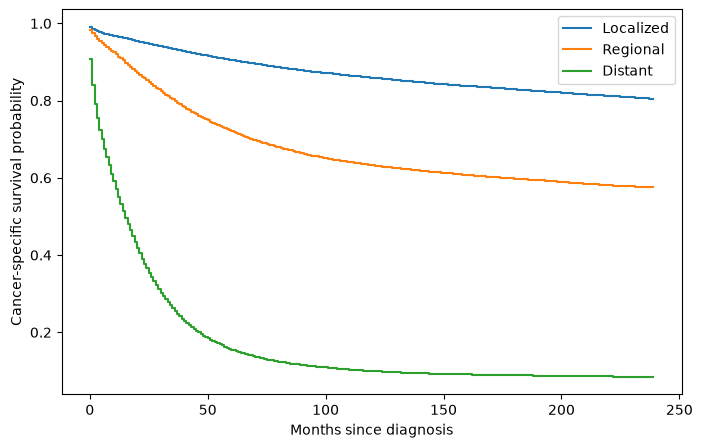

In [6]:
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

d = df[df["stage_group"].notna() & (df["cause_death"] != "Dead (missing/unknown COD)")]

kmf = KaplanMeierFitter()
fig, ax = plt.subplots(figsize=(8, 5))
for stage in ["Localized", "Regional", "Distant"]:
    g = d[d["stage_group"] == stage]
    kmf.fit(g["surv_months"], g["event_cancer"], label=stage)
    kmf.plot_survival_function(ax=ax, ci_show=False)
    print(stage, "5-year survival:", round(float(kmf.predict(60)), 3))

ax.set_xlabel("Months since diagnosis")
ax.set_ylabel("Cancer-specific survival probability")
plt.show()